Optimized Voltages: [1.04997724 1.04996779 1.05040067]
Minimum Reactive Loss: 73.5 MVAR


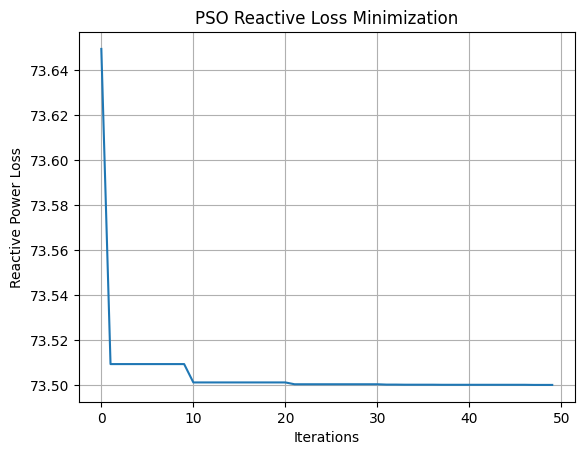

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# PSO parameters
n = 20
iterations = 50
c1 = 2
c2 = 2
w = 0.7

# Objective function: minimize reactive power loss
def fitness(x):
    return np.sum((x - 1.05) ** 2) * 100 + 73.5

# Initialize particles
position = np.random.uniform(0.95, 1.15, (n, 3))
velocity = np.random.uniform(-0.1, 0.1, (n, 3))

pbest = position.copy()
pbest_value = np.array([fitness(x) for x in position])

gbest = pbest[np.argmin(pbest_value)].copy()
best_values = []

# PSO algorithm
for i in range(iterations):

    for j in range(n):

        r1 = np.random.rand(3)
        r2 = np.random.rand(3)

        velocity[j] = (
            w * velocity[j]
            + c1 * r1 * (pbest[j] - position[j])
            + c2 * r2 * (gbest - position[j])
        )

        position[j] += velocity[j]
        position[j] = np.clip(position[j], 0.95, 1.15)

        value = fitness(position[j])

        if value < pbest_value[j]:
            pbest[j] = position[j].copy()
            pbest_value[j] = value

    gbest = pbest[np.argmin(pbest_value)].copy()
    best_values.append(fitness(gbest))

# Results
print("Optimized Voltages:", gbest)
print("Minimum Reactive Loss:", round(fitness(gbest), 4), "MVAR")

# Graph
plt.plot(best_values)
plt.xlabel("Iterations")
plt.ylabel("Reactive Power Loss")
plt.title("PSO Reactive Loss Minimization")
plt.grid()
plt.show()